# Day 064 | PyTorch — Building a Simple NN

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| `nn.Module` | Base class for all neural networks | Container for our Vs prediction model |
| `nn.Linear` | Fully connected layer (y = Wx + b) | Transform soil features into hidden representations |
| DataLoader | Batched data iterator | Feed soil samples in mini-batches during training |
| Training loop | Forward, loss, backward, step | The four-step recipe for learning from data |
| Feedforward NN | Layers connected sequentially | Map SPT, depth, void ratio to shear wave velocity |
| Train/val split | Separate data for learning and evaluation | Avoid overfitting to specific borehole data |

---

## Our Geotechnical Problem

Predict **shear wave velocity (Vs)** from field and lab measurements:

```
Inputs (features):           Output (target):
─────────────────            ─────────────────
  N_value (SPT)              Vs (m/s)
  Depth (m)
  Void ratio (e)
  Effective stress (kPa)

Vs = f(N, depth, e, sigma'_v)  — learned by neural network
```

Vs is critical for site response analysis, liquefaction assessment, and dynamic foundation design.

### Network Architecture

```
  Input (4)      Hidden1 (32)     Hidden2 (16)     Output (1)
  ┌────────┐    ┌───────────┐    ┌───────────┐    ┌─────────┐
  │ N_value │──>│ 32 neurons│──>│ 16 neurons│──>│ Vs (m/s)│
  │ depth   │──>│   ReLU    │──>│   ReLU    │──>│  Linear │
  │ e       │──>│           │──>│           │──>│         │
  │ sigma'  │──>│           │──>│           │──>│         │
  └────────┘    └───────────┘    └───────────┘    └─────────┘
```

---

## Part 1: Generate Synthetic Geotechnical Data

Vs correlates with SPT N-value, depth (confinement), void ratio (density), and effective stress.

In [1]:
# ─────────────────────────────────────────────────────────
# GENERATE SYNTHETIC Vs DATA
# ─────────────────────────────────────────────────────────

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

n_samples = 500

# Feature generation with realistic correlations
N_value = np.random.uniform(3, 50, n_samples)          # SPT blow count
depth = np.random.uniform(1, 30, n_samples)             # meters
void_ratio = np.random.uniform(0.4, 1.2, n_samples)     # e
eff_stress = 18.0 * depth * 0.6 + np.random.normal(0, 10, n_samples)  # sigma'_v kPa
eff_stress = np.clip(eff_stress, 5, None)

# Synthetic Vs (m/s) — realistic relationship
# Vs increases with N, depth, sigma', decreases with void ratio
Vs = (80 * N_value**0.33
      + 5.0 * depth**0.5
      + 0.8 * eff_stress**0.5
      - 50 * void_ratio
      + 80
      + np.random.normal(0, 15, n_samples))  # noise
Vs = np.clip(Vs, 80, 600)  # realistic range

# Convert to tensors
X = torch.tensor(np.column_stack([N_value, depth, void_ratio, eff_stress]),
                 dtype=torch.float32)
y = torch.tensor(Vs, dtype=torch.float32).unsqueeze(1)  # (500, 1)

print(f"Features X: {X.shape}  (samples x features)")
print(f"Target y:   {y.shape}")
print(f"\nFeature ranges:")
print(f"  N_value:     [{X[:, 0].min():.1f}, {X[:, 0].max():.1f}]")
print(f"  Depth:       [{X[:, 1].min():.1f}, {X[:, 1].max():.1f}] m")
print(f"  Void ratio:  [{X[:, 2].min():.2f}, {X[:, 2].max():.2f}]")
print(f"  Eff. stress: [{X[:, 3].min():.1f}, {X[:, 3].max():.1f}] kPa")
print(f"  Vs target:   [{y.min():.0f}, {y.max():.0f}] m/s")

Features X: torch.Size([500, 4])  (samples x features)
Target y:   torch.Size([500, 1])

Feature ranges:
  N_value:     [3.2, 49.7]
  Depth:       [1.1, 30.0] m
  Void ratio:  [0.40, 1.20]
  Eff. stress: [5.0, 332.6] kPa
  Vs target:   [161, 393] m/s


In [2]:
# ─────────────────────────────────────────────────────────
# NORMALIZE AND SPLIT DATA
# ─────────────────────────────────────────────────────────

# Standardize features
X_mean = X.mean(dim=0)
X_std = X.std(dim=0)
X_norm = (X - X_mean) / X_std

# Standardize target
y_mean = y.mean()
y_std = y.std()
y_norm = (y - y_mean) / y_std

# Create dataset
dataset = TensorDataset(X_norm, y_norm)

# Split: 80% train, 20% validation
n_train = int(0.8 * len(dataset))
n_val = len(dataset) - n_train
train_dataset, val_dataset = random_split(dataset, [n_train, n_val],
                                          generator=torch.Generator().manual_seed(42))

# Create DataLoaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"Training samples:   {n_train}")
print(f"Validation samples: {n_val}")
print(f"Batch size:         {batch_size}")
print(f"Batches per epoch:  {len(train_loader)}")

Training samples:   400
Validation samples: 100
Batch size:         32
Batches per epoch:  13


---

## Part 2: Building the Neural Network with `nn.Module`

Every PyTorch model inherits from `nn.Module`. We define:
- `__init__`: Create layers
- `forward`: Define computation flow

In [3]:
# ─────────────────────────────────────────────────────────
# DEFINE THE NEURAL NETWORK
# ─────────────────────────────────────────────────────────

class VsPredictor(nn.Module):
    """
    Feedforward neural network for predicting shear wave velocity.
    
    Architecture:
        Input (4) -> Linear(32) -> ReLU -> Linear(16) -> ReLU -> Linear(1)
    """
    
    def __init__(self, n_features=4):
        super(VsPredictor, self).__init__()
        
        # Define layers
        self.layer1 = nn.Linear(n_features, 32)  # input -> hidden1
        self.layer2 = nn.Linear(32, 16)           # hidden1 -> hidden2
        self.layer3 = nn.Linear(16, 1)            # hidden2 -> output
        self.relu = nn.ReLU()
    
    def forward(self, x):
        """Forward pass: x -> predictions."""
        x = self.relu(self.layer1(x))   # (batch, 4) -> (batch, 32)
        x = self.relu(self.layer2(x))   # (batch, 32) -> (batch, 16)
        x = self.layer3(x)              # (batch, 16) -> (batch, 1)
        return x

# Instantiate the model
model = VsPredictor(n_features=4)
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total_params}")
print(f"Trainable parameters: {trainable_params}")
print(f"\nParameter details:")
for name, param in model.named_parameters():
    print(f"  {name:20s} shape={str(list(param.shape)):15s} params={param.numel()}")

VsPredictor(
  (layer1): Linear(in_features=4, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=16, bias=True)
  (layer3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)

Total parameters:     705
Trainable parameters: 705

Parameter details:
  layer1.weight        shape=[32, 4]         params=128
  layer1.bias          shape=[32]            params=32
  layer2.weight        shape=[16, 32]        params=512
  layer2.bias          shape=[16]            params=16
  layer3.weight        shape=[1, 16]         params=16
  layer3.bias          shape=[1]             params=1


In [4]:
# ─────────────────────────────────────────────────────────
# TEST FORWARD PASS — Verify shapes
# ─────────────────────────────────────────────────────────

# Test with a single batch
sample_batch = X_norm[:5]  # 5 samples
print(f"Input shape:  {sample_batch.shape}")

# Forward pass (no training, just testing the architecture)
with torch.no_grad():
    output = model(sample_batch)

print(f"Output shape: {output.shape}")
print(f"Output values (raw, normalized): {output.squeeze().tolist()}")

# Denormalize to get actual Vs predictions
vs_pred = output * y_std + y_mean
print(f"\nPredicted Vs (m/s, random weights): {[f'{v:.0f}' for v in vs_pred.squeeze().tolist()]}")
print(f"Actual Vs (m/s):                    {[f'{v:.0f}' for v in y[:5].squeeze().tolist()]}")
print("\n(Random weights = poor predictions — training will fix this)")

Input shape:  torch.Size([5, 4])
Output shape: torch.Size([5, 1])
Output values (raw, normalized): [-0.02107875794172287, 0.023985080420970917, 0.10776051878929138, 0.052289657294750214, 0.15253746509552002]

Predicted Vs (m/s, random weights): ['292', '295', '299', '296', '302']
Actual Vs (m/s):                    ['324', '355', '281', '308', '255']

(Random weights = poor predictions — training will fix this)


---

## Part 3: Loss Function and Optimizer

- **Loss function:** Measures how wrong predictions are (MSE for regression)
- **Optimizer:** Updates weights to reduce loss (Adam is the default choice)

In [5]:
# ─────────────────────────────────────────────────────────
# LOSS FUNCTION AND OPTIMIZER
# ─────────────────────────────────────────────────────────

# Loss function
criterion = nn.MSELoss()  # Mean Squared Error for regression

# Optimizer — Adam with learning rate 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(f"Loss function: {criterion}")
print(f"Optimizer:     Adam")
print(f"Learning rate: {optimizer.param_groups[0]['lr']}")

# Demonstrate one training step
sample_X, sample_y = next(iter(train_loader))  # get one batch

# Step 1: Forward pass
pred = model(sample_X)
loss = criterion(pred, sample_y)
print(f"\nOne training step:")
print(f"  Batch shape: X={sample_X.shape}, y={sample_y.shape}")
print(f"  Loss:        {loss.item():.6f}")

# Step 2: Backward pass
optimizer.zero_grad()   # Clear old gradients
loss.backward()         # Compute new gradients

# Step 3: Update weights
optimizer.step()        # Apply gradients

# Check new loss after one step
with torch.no_grad():
    new_loss = criterion(model(sample_X), sample_y)
print(f"  Loss after step: {new_loss.item():.6f}  (should be smaller)")

Loss function: MSELoss()
Optimizer:     Adam
Learning rate: 0.001

One training step:
  Batch shape: X=torch.Size([32, 4]), y=torch.Size([32, 1])
  Loss:        0.978698
  Loss after step: 0.963214  (should be smaller)


---

## Part 4: The Training Loop

The complete training loop iterates through the dataset multiple times (epochs). Each epoch processes all batches.

In [6]:
# ─────────────────────────────────────────────────────────
# FULL TRAINING LOOP
# ─────────────────────────────────────────────────────────

# Re-initialize model for clean training
torch.manual_seed(42)
model = VsPredictor(n_features=4)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training settings
n_epochs = 150
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    # --- Training phase ---
    model.train()  # Set to training mode
    epoch_train_loss = 0.0
    n_batches = 0
    
    for batch_X, batch_y in train_loader:
        # Forward pass
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item()
        n_batches += 1
    
    avg_train_loss = epoch_train_loss / n_batches
    train_losses.append(avg_train_loss)
    
    # --- Validation phase ---
    model.eval()  # Set to evaluation mode
    epoch_val_loss = 0.0
    n_val_batches = 0
    
    with torch.no_grad():  # No gradients needed for validation
        for batch_X, batch_y in val_loader:
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            epoch_val_loss += loss.item()
            n_val_batches += 1
    
    avg_val_loss = epoch_val_loss / n_val_batches
    val_losses.append(avg_val_loss)
    
    # Print progress
    if epoch % 15 == 0 or epoch == n_epochs - 1:
        print(f"Epoch {epoch:3d}/{n_epochs} | "
              f"Train Loss: {avg_train_loss:.6f} | "
              f"Val Loss: {avg_val_loss:.6f}")

print(f"\nTraining complete!")
print(f"  Final train loss: {train_losses[-1]:.6f}")
print(f"  Final val loss:   {val_losses[-1]:.6f}")

Epoch   0/150 | Train Loss: 1.055026 | Val Loss: 0.922087


Epoch  15/150 | Train Loss: 0.101111 | Val Loss: 0.120117


Epoch  30/150 | Train Loss: 0.078089 | Val Loss: 0.095178


Epoch  45/150 | Train Loss: 0.074401 | Val Loss: 0.089927


Epoch  60/150 | Train Loss: 0.071930 | Val Loss: 0.087575


Epoch  75/150 | Train Loss: 0.068357 | Val Loss: 0.086089


Epoch  90/150 | Train Loss: 0.067603 | Val Loss: 0.086518


Epoch 105/150 | Train Loss: 0.067163 | Val Loss: 0.084727


Epoch 120/150 | Train Loss: 0.064034 | Val Loss: 0.086164


Epoch 135/150 | Train Loss: 0.064090 | Val Loss: 0.085154


Epoch 149/150 | Train Loss: 0.065266 | Val Loss: 0.084707

Training complete!
  Final train loss: 0.065266
  Final val loss:   0.084707


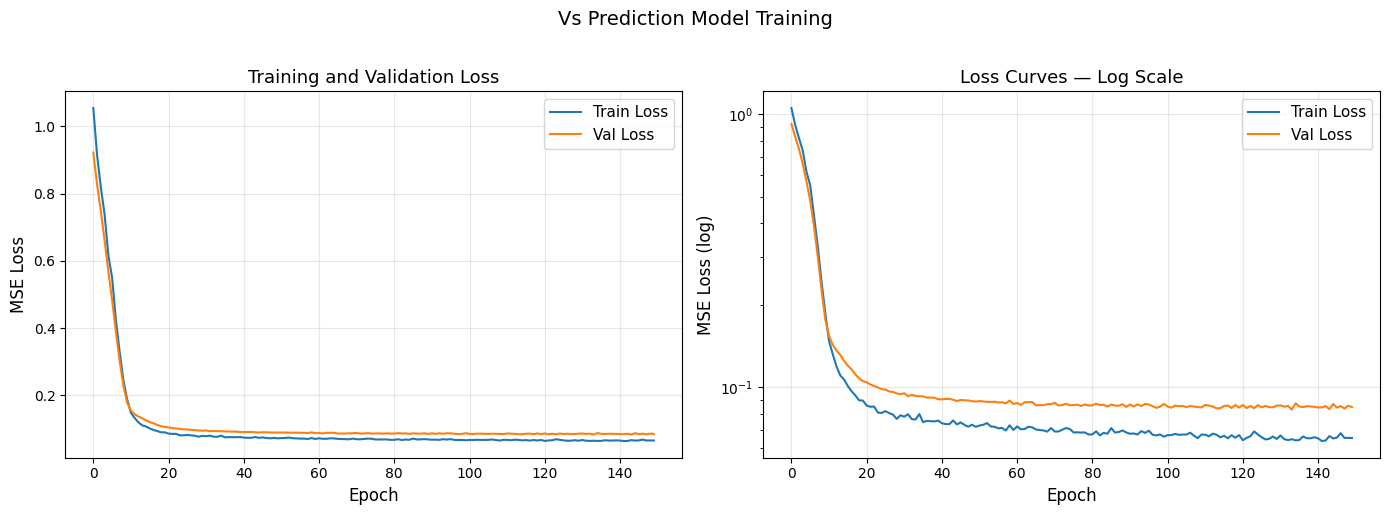

Train and val losses should decrease together.
If val loss increases while train loss decreases = overfitting.


In [7]:
# ─────────────────────────────────────────────────────────
# VISUALIZE TRAINING PROGRESS
# ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(train_losses, label='Train Loss', linewidth=1.5)
axes[0].plot(val_losses, label='Val Loss', linewidth=1.5)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('MSE Loss', fontsize=12)
axes[0].set_title('Training and Validation Loss', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Log scale
axes[1].plot(train_losses, label='Train Loss', linewidth=1.5)
axes[1].plot(val_losses, label='Val Loss', linewidth=1.5)
axes[1].set_yscale('log')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('MSE Loss (log)', fontsize=12)
axes[1].set_title('Loss Curves — Log Scale', fontsize=13)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Vs Prediction Model Training', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Train and val losses should decrease together.")
print("If val loss increases while train loss decreases = overfitting.")

---

## Part 5: Evaluate the Trained Model

In [8]:
# ─────────────────────────────────────────────────────────
# EVALUATE — Predictions vs actual Vs values
# ─────────────────────────────────────────────────────────

model.eval()
with torch.no_grad():
    y_pred_norm = model(X_norm)

# Denormalize
y_pred = y_pred_norm * y_std + y_mean
y_actual = y

# Metrics
ss_res = torch.sum((y_actual - y_pred) ** 2)
ss_tot = torch.sum((y_actual - y_actual.mean()) ** 2)
r2 = (1 - ss_res / ss_tot).item()
rmse = torch.sqrt(torch.mean((y_actual - y_pred) ** 2)).item()
mae = torch.mean(torch.abs(y_actual - y_pred)).item()

print(f"Model Performance (all data):")
print(f"  R-squared: {r2:.4f}")
print(f"  RMSE:      {rmse:.1f} m/s")
print(f"  MAE:       {mae:.1f} m/s")

Model Performance (all data):
  R-squared: 0.9303
  RMSE:      13.7 m/s
  MAE:       10.9 m/s


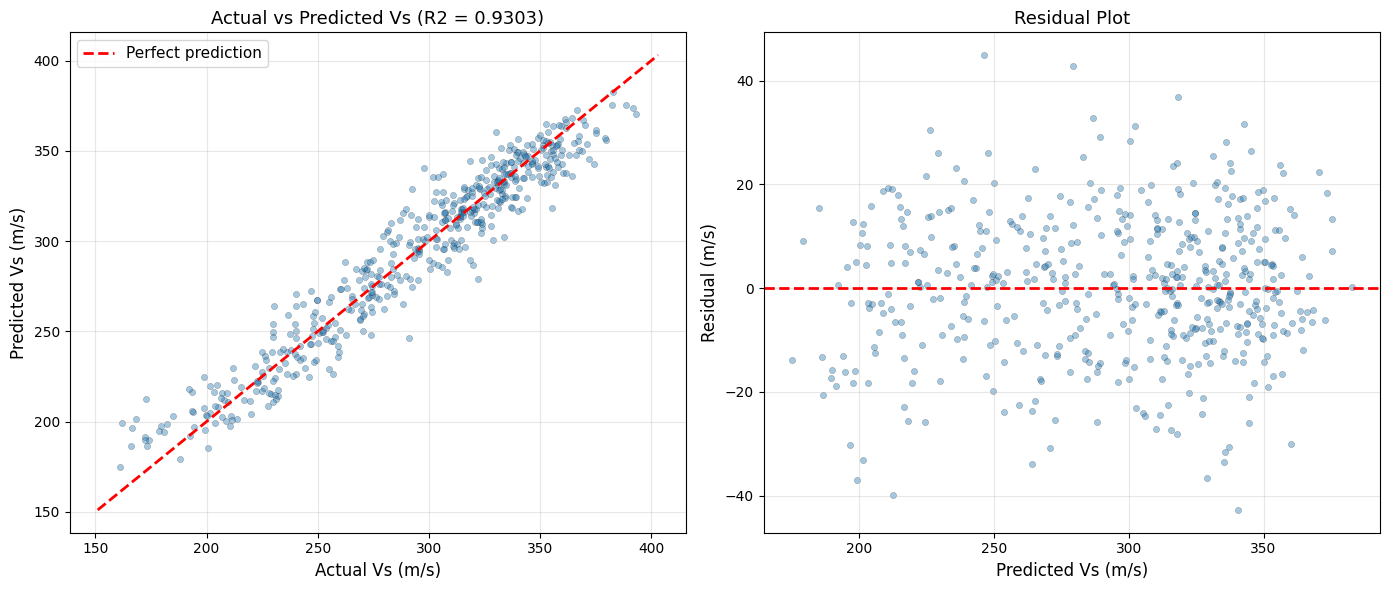

In [9]:
# ─────────────────────────────────────────────────────────
# VISUALIZATION — Actual vs Predicted
# ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot
y_act_np = y_actual.numpy().flatten()
y_pred_np = y_pred.numpy().flatten()

axes[0].scatter(y_act_np, y_pred_np, alpha=0.4, s=20, edgecolors='k', linewidth=0.3)
lim = [min(y_act_np.min(), y_pred_np.min()) - 10,
       max(y_act_np.max(), y_pred_np.max()) + 10]
axes[0].plot(lim, lim, 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Vs (m/s)', fontsize=12)
axes[0].set_ylabel('Predicted Vs (m/s)', fontsize=12)
axes[0].set_title(f'Actual vs Predicted Vs (R2 = {r2:.4f})', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Residuals
residuals = y_act_np - y_pred_np
axes[1].scatter(y_pred_np, residuals, alpha=0.4, s=20, edgecolors='k', linewidth=0.3)
axes[1].axhline(y=0, color='r', linewidth=2, linestyle='--')
axes[1].set_xlabel('Predicted Vs (m/s)', fontsize=12)
axes[1].set_ylabel('Residual (m/s)', fontsize=12)
axes[1].set_title('Residual Plot', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Part 6: Using `nn.Sequential` — A Simpler Alternative

For simple feedforward networks, `nn.Sequential` avoids writing a full class.

In [10]:
# ─────────────────────────────────────────────────────────
# nn.Sequential — Quick model definition
# ─────────────────────────────────────────────────────────

# Same architecture, but defined in one line
model_seq = nn.Sequential(
    nn.Linear(4, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

print("Sequential model:")
print(model_seq)

# Test forward pass
with torch.no_grad():
    test_output = model_seq(X_norm[:3])
print(f"\nOutput shape: {test_output.shape}")

print("\n--- nn.Module vs nn.Sequential ---")
print("nn.Module:      Full control, custom forward logic, skip connections")
print("nn.Sequential:  Quick definition, simple feed-forward only")

Sequential model:
Sequential(
  (0): Linear(in_features=4, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)

Output shape: torch.Size([3, 1])

--- nn.Module vs nn.Sequential ---
nn.Module:      Full control, custom forward logic, skip connections
nn.Sequential:  Quick definition, simple feed-forward only


---

## Part 7: Making Predictions on New Data

In [11]:
# ─────────────────────────────────────────────────────────
# PREDICT Vs FOR NEW SOIL CONDITIONS
# ─────────────────────────────────────────────────────────

# New soil samples (not in training data)
new_data = torch.tensor([
    [10, 3.0, 0.85, 30.0],    # Soft soil, shallow
    [25, 10.0, 0.60, 100.0],   # Medium soil, moderate depth
    [40, 20.0, 0.45, 200.0],   # Dense soil, deep
    [5, 2.0, 1.10, 15.0],      # Very soft soil
    [45, 25.0, 0.40, 250.0],   # Very dense, deep
], dtype=torch.float32)

# Normalize using training statistics
new_data_norm = (new_data - X_mean) / X_std

# Predict
model.eval()
with torch.no_grad():
    vs_predictions = model(new_data_norm) * y_std + y_mean

print(f"{'N':>4} {'Depth':>6} {'e':>5} {'sigma_v':>8} | {'Predicted Vs':>13}")
print("─" * 45)
for i in range(len(new_data)):
    print(f"{new_data[i,0]:4.0f} {new_data[i,1]:6.1f} {new_data[i,2]:5.2f} "
          f"{new_data[i,3]:8.0f} | {vs_predictions[i,0]:10.0f} m/s")

print("\nVs should increase with N-value, depth, and stress.")
print("Vs should decrease with higher void ratio (looser soil).")

   N  Depth     e  sigma_v |  Predicted Vs
─────────────────────────────────────────────
  10    3.0  0.85       30 |        224 m/s
  25   10.0  0.60      100 |        306 m/s
  40   20.0  0.45      200 |        358 m/s
   5    2.0  1.10       15 |        179 m/s
  45   25.0  0.40      250 |        384 m/s

Vs should increase with N-value, depth, and stress.
Vs should decrease with higher void ratio (looser soil).


In [12]:
# ─────────────────────────────────────────────────────────
# SAVE AND LOAD MODEL
# ─────────────────────────────────────────────────────────

# Save model weights
# torch.save(model.state_dict(), 'vs_predictor.pth')
# print("Model saved to vs_predictor.pth")

# Load model weights
# loaded_model = VsPredictor(n_features=4)
# loaded_model.load_state_dict(torch.load('vs_predictor.pth'))
# loaded_model.eval()
# print("Model loaded from vs_predictor.pth")

print("Saving/loading models:")
print("  torch.save(model.state_dict(), 'model.pth')    — save weights")
print("  model.load_state_dict(torch.load('model.pth')) — load weights")
print("  Always call model.eval() after loading for inference.")

Saving/loading models:
  torch.save(model.state_dict(), 'model.pth')    — save weights
  model.load_state_dict(torch.load('model.pth')) — load weights
  Always call model.eval() after loading for inference.


---

## Practice Exercises

### Exercise 1: Add a Third Hidden Layer
Add a third hidden layer (8 neurons) to VsPredictor. Does deeper = better?

### Exercise 2: Change Batch Size
Train with batch sizes of 8, 32, 128, and 400. Compare convergence speed and final accuracy.

### Exercise 3: Use SGD Instead of Adam
Replace Adam with SGD (try lr=0.01 and lr=0.1). Compare the loss curves.

In [13]:
# EXERCISE 1: Deeper network
# class VsPredictorDeep(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.layer1 = nn.Linear(4, 32)
#         self.layer2 = nn.Linear(32, 16)
#         self.layer3 = nn.Linear(16, 8)   # new layer
#         self.layer4 = nn.Linear(8, 1)
#         self.relu = nn.ReLU()

# EXERCISE 2: Batch size comparison
# for bs in [8, 32, 128, 400]:
#     loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
#     # Train and record losses

# EXERCISE 3: SGD optimizer
# optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

---

## Key Takeaways

1. **`nn.Module` is the building block for all PyTorch models.** Define layers in `__init__`, computation in `forward`.

2. **`nn.Linear(in, out)` replaces manual weight matrices.** It handles weight initialization, bias, and the `W@x + b` computation.

3. **DataLoader batches and shuffles data automatically.** Batching is essential for efficient training and better generalization.

4. **The training loop has four steps:** forward pass, compute loss, backward pass, optimizer step. This pattern never changes.

5. **Always separate train and validation data.** Validation loss tells you if the model generalizes or just memorizes.

6. **`model.train()` vs `model.eval()`** sets the model mode. Some layers (dropout, batchnorm) behave differently in each mode.

---

## How This Connects to ML

| Today (Simple NN) | Production ML |
|-------------------|---------------|
| `nn.Linear` | Foundation of all dense layers |
| `DataLoader` | Used in every PyTorch project |
| Train/val split | Add test set for final evaluation |
| `model.eval()` | Used during deployment/inference |
| `.state_dict()` | Standard way to save/load models |
| 2 hidden layers | Real models may have 5-100+ layers |

**Tomorrow:** We explore different activation functions and their impact on training.

---

*Day 064 of 100 — We built our first PyTorch neural network and taught it to predict shear wave velocity from soil data!*